Shape: (36733, 12)


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


Rows per year: {2011: 7411, 2012: 7628, 2013: 7152, 2014: 7158, 2015: 7384}
Missing values: 0
Duplicate rows (all sensors identical): 7


,count,mean,std,min,25%,50%,75%,max
AT,36733.0,17.71,7.45,-6.23,11.78,17.80,23.66,37.10
AP,36733.0,1013.07,6.46,985.85,1008.80,1012.60,1017.00,1036.60
AH,36733.0,77.87,14.46,24.08,68.19,80.47,89.38,100.20
AFDP,36733.0,3.93,0.77,2.09,3.36,3.94,4.38,7.61
GTEP,36733.0,25.56,4.20,17.70,23.13,25.10,29.06,40.72
TIT,36733.0,1081.43,17.54,1000.80,1071.80,1085.90,1097.00,1100.90
TAT,36733.0,546.16,6.84,511.04,544.72,549.88,550.04,550.61
TEY,36733.0,133.51,15.62,100.02,124.45,133.73,144.08,179.50
CDP,36733.0,12.06,1.09,9.85,11.44,11.96,12.86,15.16
CO,36733.0,2.37,2.26,0.00,1.18,1.71,2.84,44.10


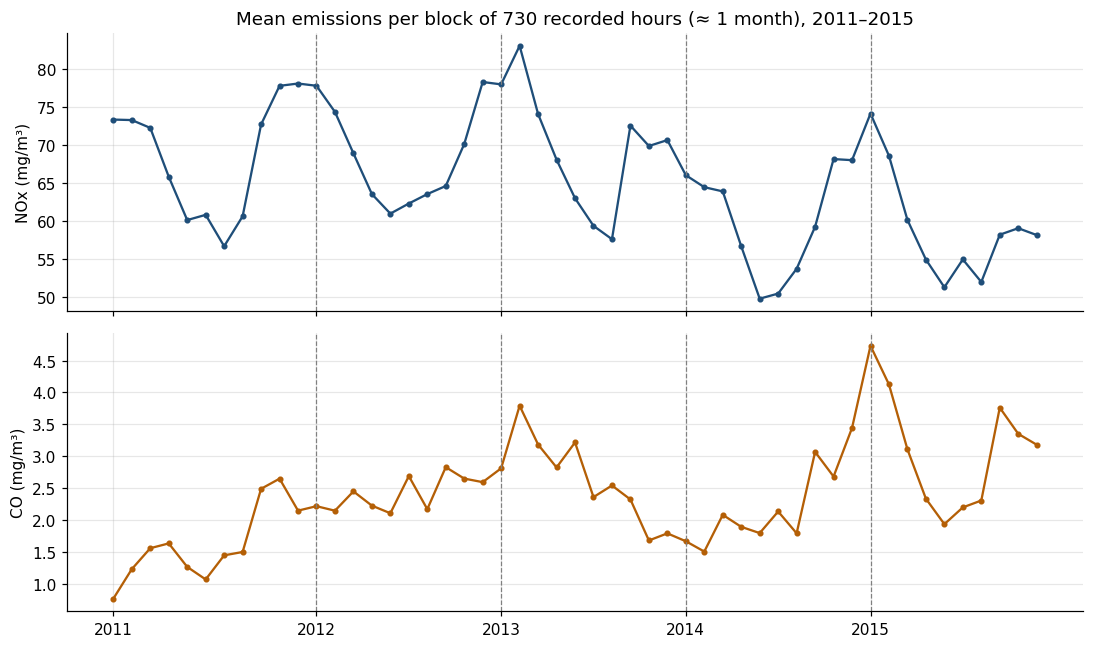

Mean NOx by year: {2011: 67.6, 2012: 68.8, 2013: 70.0, 2014: 60.1, 2015: 59.9}


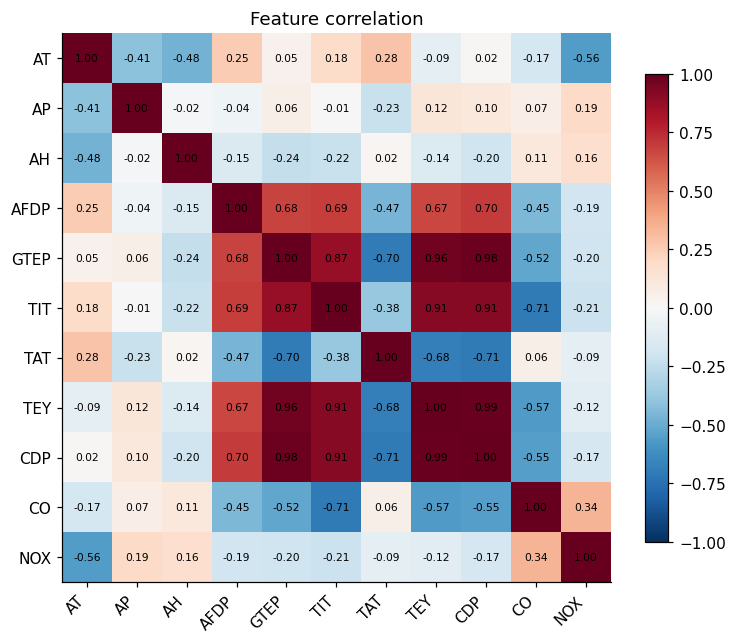

Correlation CDP–TEY: 0.989
Train (2011–2013): 22191 rows | Test (2014–2015): 14542 rows


,MAE,RMSE,R2,within_10pct
Static Ridge (temporal),8.383,10.387,0.036,41.267
Static RandomForest (temporal),10.619,12.154,-0.320,23.821
Static GradientBoosting (temporal),11.014,12.421,-0.379,20.121
RandomForest (random split),2.837,4.416,0.853,90.370


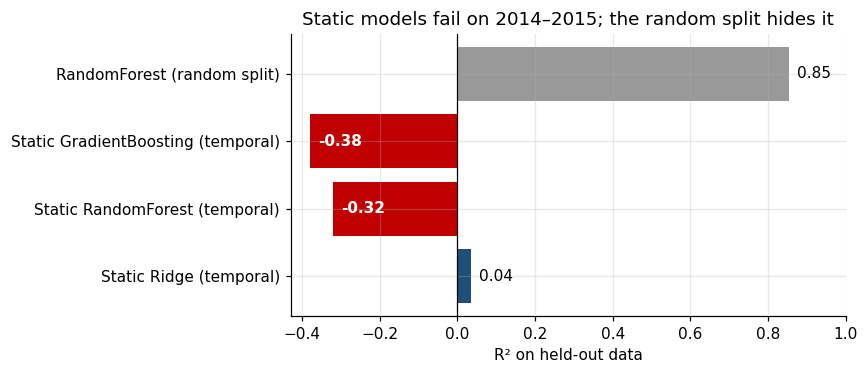

Mean bias of static GradientBoosting on 2014–2015: +10.39 mg/m³ (over-prediction)
Validation done in 38 s


,MAE,RMSE,R2,within_10pct
1 month,4.227,6.418,0.716,82.942
3 months,4.279,6.352,0.722,82.774
6 months,4.225,6.226,0.733,83.375
12 months,4.348,6.399,0.718,82.383
All history,4.548,6.445,0.714,81.096


Windows within 1% of best MAE: ['1 month', '6 months']
Chosen window: 6 months
Test run done in 15 s


,MAE,RMSE,R2,within_10pct
Static GradientBoosting,11.014,12.421,-0.379,20.121
"Weekly retrain, 6 months window",3.423,5.154,0.763,83.792


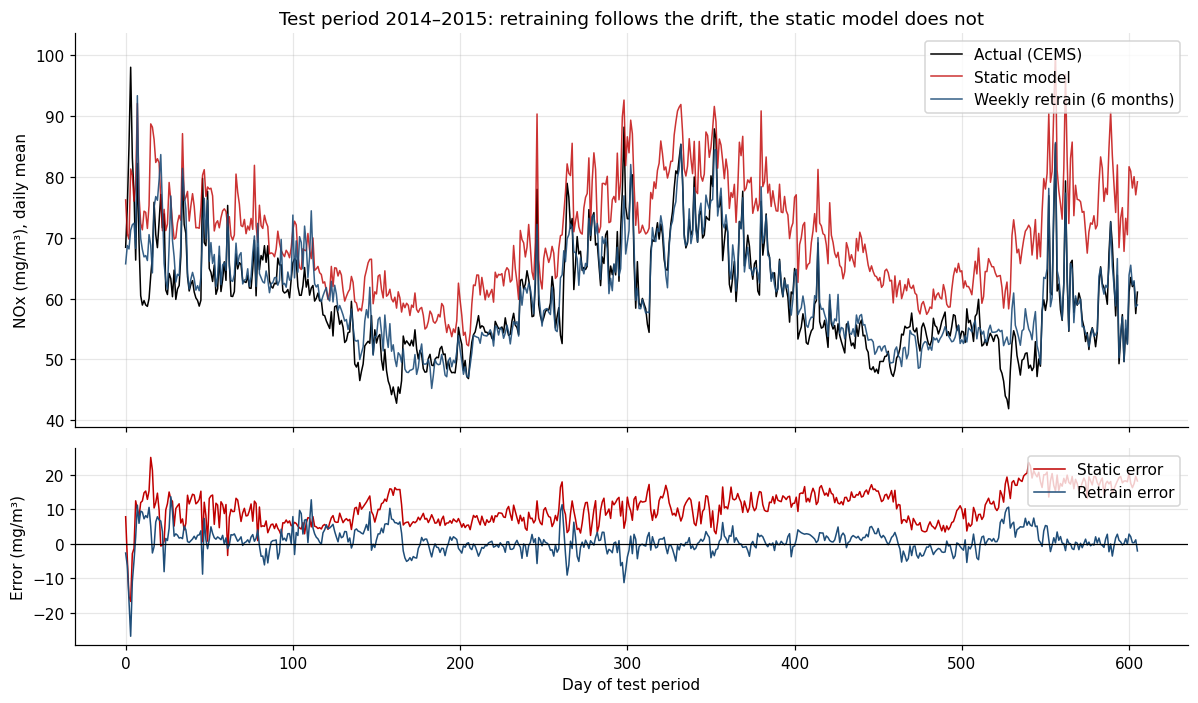

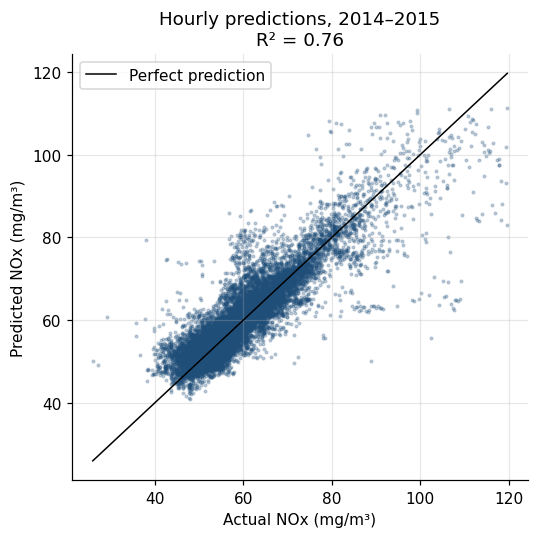

,Outage,Method,MAE,RMSE,R2,within_10pct
0,1 day,PEMS,2.741,4.137,0.832,89.511
1,1 day,Hold last CEMS value,5.833,10.089,0.000,74.330
2,3 days,PEMS,3.030,4.683,0.807,87.835
3,3 days,Hold last CEMS value,6.329,10.470,0.033,69.045
4,7 days,PEMS,3.193,4.866,0.788,86.136
5,7 days,Hold last CEMS value,6.848,10.976,-0.079,64.279


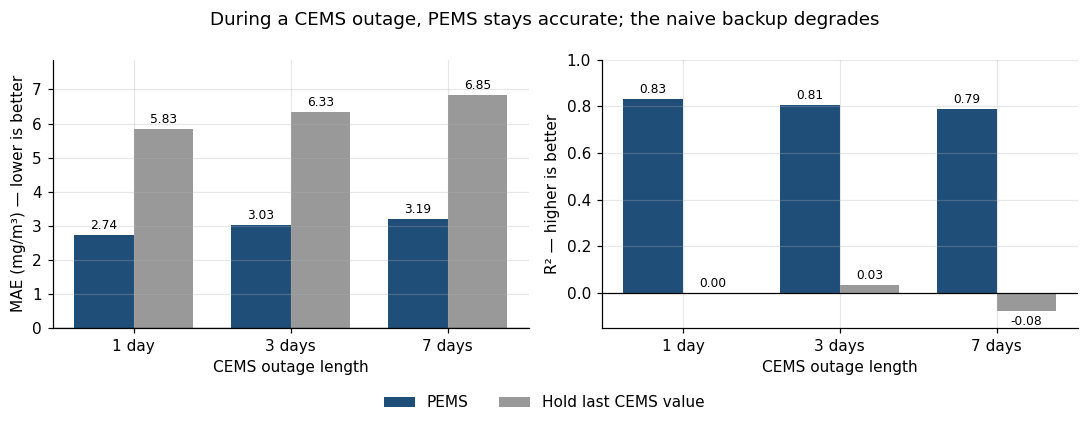

Example outage starts at row 27399


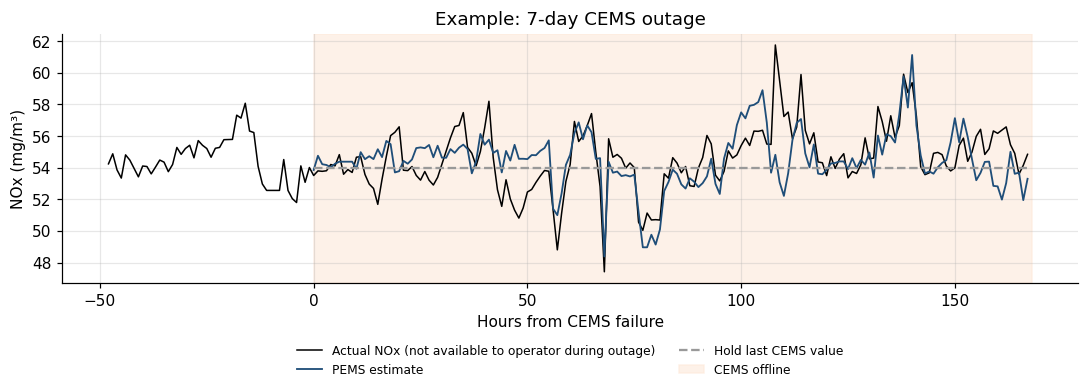

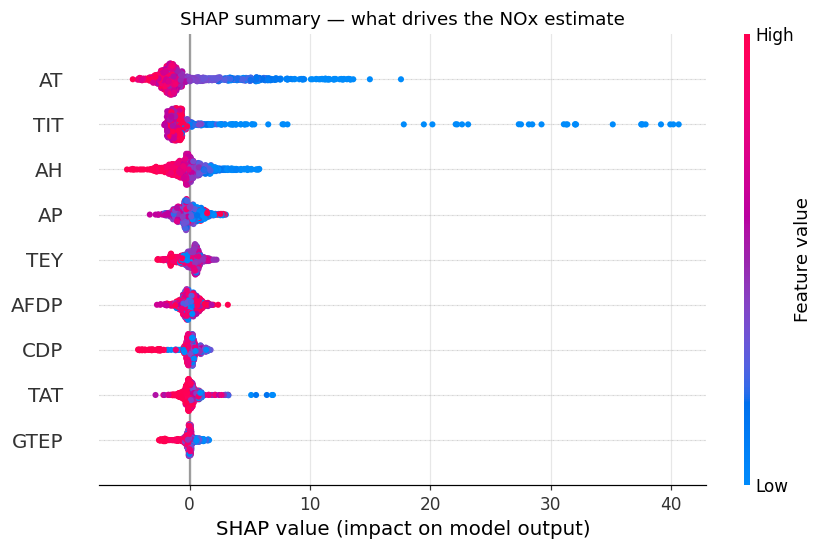

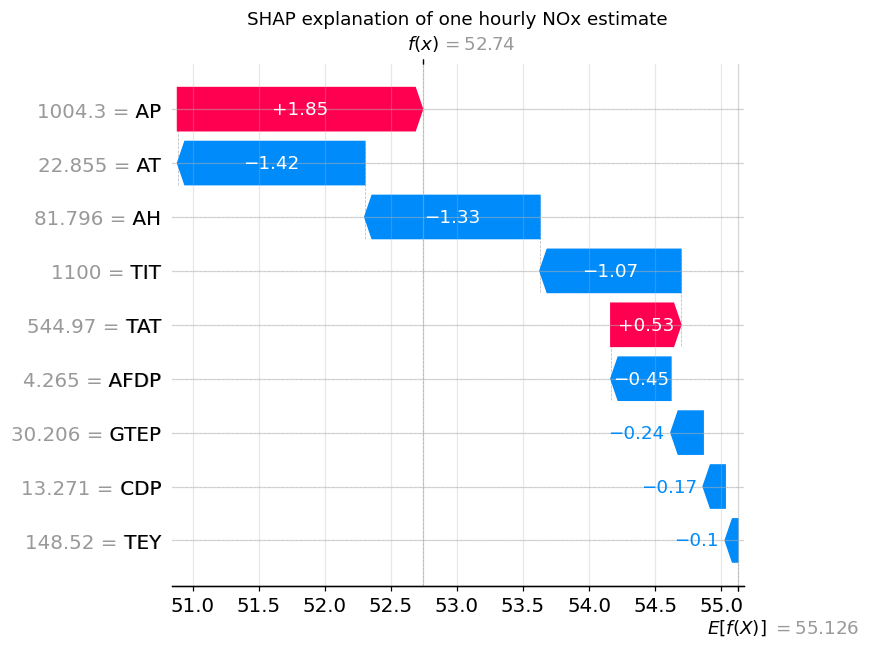

CO skewness: 4.84 | NOx skewness: 1.03
Static RandomForest on CO, test 2014–2015: {'MAE': 0.832, 'RMSE': 1.396, 'R2': 0.593}
Benchmark in Kaya et al. (2019) for CO: MAE 0.927, R² 0.584


,MAE,RMSE,R2,within_10pct
Experiment,,,,
Static GradientBoosting (temporal test),11.014,12.421,-0.379,20.121
"RandomForest, random split (leaky)",2.837,4.416,0.853,90.370
"Weekly retrain, 6 months window",3.423,5.154,0.763,83.792
CEMS out 7 days — PEMS,3.193,4.866,0.788,86.136
CEMS out 7 days — hold last value,6.848,10.976,-0.079,64.279
"Benchmark: Kaya et al. (2019), NOx",7.910,NaN,0.638,NaN


In [ ]:
# ==============================================================================
# DENG611 ASSESSMENT 3A - ML-BASED PEMS FOR NOX AT A GAS TURBINE POWER PLANT
# ==============================================================================
# Case study: a Predictive Emission Monitoring System (PEMS) that estimates hourly NOx from
# process and ambient sensor data, as a backup when the Continuous Emission Monitoring System
# (CEMS) is offline. Context: Indonesian gas turbine and combined cycle plants.
#
# Dataset: UCI Gas Turbine CO and NOx Emission Data Set (Kaya, Tüfekci & Uzun, 2019), 36,733
# hourly records, 2011–2015.
#
# Notebook structure
#   1. Setup and data loading
#   2. Data validation and exploration
#   3. Experiment 1 — static model vs random split (why a temporal split is needed)
#   4. Experiment 2 — weekly retraining with a sliding window (window chosen on 2013 validation)
#   5. Experiment 3 — CEMS outage simulation (PEMS vs holding the last CEMS value)
#   6. Interpretability with SHAP
#   7. CO as a comparison target
#   8. Results summary


# ==============================================================================
# 1. SETUP AND DATA LOADING
# ==============================================================================

import time
import warnings
from pathlib import Path
from IPython.display import display
warnings.filterwarnings("ignore")   # hide library deprecation/progress warnings in the demo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# SHAP is installed automatically into THIS kernel's Python if it is missing
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap"])
    import shap
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42                      # fixed seed so results are reproducible
DATA_DIR = Path("data")        # folder holding gt_2011.csv ... gt_2015.csv
FIG_DIR = Path("figures")      # every figure is also saved here for the report
FIG_DIR.mkdir(exist_ok=True)

FEATURES = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
TARGET = "NOX"
# The dataset has no timestamps and holds ~84% of calendar hours (only recorded operating hours),
# so every window below is counted in RECORDS (recorded hours), e.g. a "week" = 168 records.
HOURS_PER_WEEK = 168
HOURS_PER_MONTH = 730          # 8760 / 12; in records this spans slightly more than a calendar month

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# Load the five yearly files and keep the chronological order.
# A 'year' column is added for the temporal split; it is NOT used as a model feature.
frames = []
for year in range(2011, 2016):
    f = pd.read_csv(DATA_DIR / f"gt_{year}.csv")
    f["year"] = year
    frames.append(f)
df = pd.concat(frames, ignore_index=True)

print("Shape:", df.shape)
display(df.head())


# ==============================================================================
# 2. DATA VALIDATION AND EXPLORATION
# ==============================================================================

# Basic quality checks: rows per year, missing values, duplicate measurements
print("Rows per year:", df["year"].value_counts().sort_index().to_dict())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows (all sensors identical):", int(df.duplicated(subset=FEATURES + ["CO", "NOX"]).sum()))
display(df[FEATURES + ["CO", "NOX"]].describe().T.round(2))

# Mean NOx and CO for every block of 730 records (roughly one month), with year boundaries.
# This is the key exploratory plot: NOx drops by ~10 mg/m3 from 2014 onwards.
block = np.arange(len(df)) // HOURS_PER_MONTH
monthly = df.groupby(block).agg(NOX=("NOX", "mean"), CO=("CO", "mean"), year=("year", "first"))

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(monthly.index, monthly["NOX"], marker="o", ms=3, color="#1f4e79")
ax[0].set_ylabel("NOx (mg/m³)")
ax[0].set_title("Mean emissions per block of 730 recorded hours (≈ 1 month), 2011–2015")
ax[1].plot(monthly.index, monthly["CO"], marker="o", ms=3, color="#b45f06")
ax[1].set_ylabel("CO (mg/m³)")
for a in ax:
    for y in range(2012, 2016):
        x = monthly.index[monthly["year"] == y][0]
        a.axvline(x, color="grey", ls="--", lw=0.8)
ax[1].set_xticks([monthly.index[monthly["year"] == y][0] for y in range(2011, 2016)])
ax[1].set_xticklabels(range(2011, 2016))
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_monthly_emissions.png"); plt.show()

print("Mean NOx by year:", df.groupby("year")["NOX"].mean().round(1).to_dict())

# Reading the plot: NOx follows a seasonal cycle (higher in the cooler months) and, on top of
# that, its level drops by about 10 mg/m³ from 2014. The input sensors do not shift by a
# comparable amount, which is the signature of concept drift.

# Correlation heatmap: shows strongly collinear features (e.g. CDP vs TEY)
corr = df[FEATURES + ["CO", "NOX"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, shrink=0.8)
ax.set_title("Feature correlation")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_correlation.png"); plt.show()
print("Correlation CDP–TEY:", round(corr.loc["CDP", "TEY"], 3))


# ==============================================================================
# 3. EXPERIMENT 1 - STATIC MODEL VS RANDOM SPLIT
# ==============================================================================
# Protocol from the original paper: train 2011–2012, validate 2013, test 2014–2015. Here the
# static model is trained once on all data before the test period (2011–2013) and never updated.
#
# For contrast, the same model is also evaluated with a random 60/40 split, which mixes future
# hours into training. This shows why a random split gives a misleadingly good result for time-
# ordered plant data.

def evaluate(y_true, y_pred):
    """Return the metrics used throughout the report."""
    err = np.abs(y_pred - y_true)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "within_10pct": np.mean(err / y_true <= 0.10) * 100}

def make_models():
    """Three candidate models: a linear baseline and two tree ensembles."""
    return {"Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
            "RandomForest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                  n_jobs=-1, random_state=SEED),
            "GradientBoosting": HistGradientBoostingRegressor(random_state=SEED)}

train = df[df["year"] <= 2013]
test = df[df["year"] >= 2014]
print(f"Train (2011–2013): {len(train)} rows | Test (2014–2015): {len(test)} rows")

static_results, static_preds = {}, {}
for name, model in make_models().items():
    model.fit(train[FEATURES], train[TARGET])
    pred = model.predict(test[FEATURES])
    static_preds[name] = pred
    static_results[f"Static {name} (temporal)"] = evaluate(test[TARGET].values, pred)

# Random split for comparison (data leakage from the future)
Xtr, Xte, ytr, yte = train_test_split(df[FEATURES], df[TARGET], test_size=0.4, random_state=SEED)
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
static_results["RandomForest (random split)"] = evaluate(yte.values, rf.predict(Xte))

display(pd.DataFrame(static_results).T.round(3))

res1 = pd.DataFrame(static_results).T
fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ["#c00000" if r < 0 else "#1f4e79" for r in res1["R2"]]
colors[-1] = "#999999"
ax.barh(res1.index, res1["R2"], color=colors)
ax.axvline(0, color="black", lw=0.8)
for i, v in enumerate(res1["R2"]):
    if v >= 0:
        ax.text(v + 0.02, i, f"{v:.2f}", va="center", ha="left")
    else:  # label inside the bar so it does not collide with the axis labels
        ax.text(v + 0.02, i, f"{v:.2f}", va="center", ha="left", color="white", fontweight="bold")
ax.set_xlim(min(res1["R2"].min() - 0.05, -0.1), 1.0)
ax.set_xlabel("R² on held-out data")
ax.set_title("Static models fail on 2014–2015; the random split hides it")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_static_vs_random.png"); plt.show()

bias = np.mean(static_preds["GradientBoosting"] - test[TARGET].values)
print(f"Mean bias of static GradientBoosting on 2014–2015: {bias:+.2f} mg/m³ (over-prediction)")


# ==============================================================================
# 4. EXPERIMENT 2 - WEEKLY RETRAINING WITH A SLIDING WINDOW
# ==============================================================================
# Every week the model is retrained on only the most recent N months of data, then used for the
# following week. This mimics a PEMS that learns from recent CEMS readings.
#
# Units: windows are counted in recorded hours (records), because the data has no timestamps and
# covers about 84% of calendar hours. A "week" is 168 records and "6 months" is 4,380 records
# (about 7 calendar months).
#
# Step A — choose N on the 2013 validation year only. Selection rule (fixed before looking at
# the test set): lowest MAE; if several windows are within 1% of the best MAE, take the one with
# the highest R².
#
# Step B — run the chosen setting once on 2014–2015.

def rolling_predict(data, eval_start, eval_end, window_hours, retrain_every=HOURS_PER_WEEK):
    """Walk forward through [eval_start, eval_end): retrain on the last `window_hours`
    rows before each block, then predict the block. Uses past data only."""
    preds = []
    for start in range(eval_start, eval_end, retrain_every):
        end = min(start + retrain_every, eval_end)
        lo = 0 if window_hours is None else max(0, start - window_hours)
        model = HistGradientBoostingRegressor(random_state=SEED)
        model.fit(data.iloc[lo:start][FEATURES], data.iloc[lo:start][TARGET])
        preds.append(model.predict(data.iloc[start:end][FEATURES]))
    return np.concatenate(preds)

WINDOWS = {"1 month": 1 * HOURS_PER_MONTH, "3 months": 3 * HOURS_PER_MONTH,
           "6 months": 6 * HOURS_PER_MONTH, "12 months": 12 * HOURS_PER_MONTH,
           "All history": None}

val_start = df.index[df["year"] == 2013][0]
val_end = df.index[df["year"] == 2013][-1] + 1
y_val = df[TARGET].values[val_start:val_end]

t0 = time.time()
val_results = {name: evaluate(y_val, rolling_predict(df, val_start, val_end, w))
               for name, w in WINDOWS.items()}
val_table = pd.DataFrame(val_results).T
print(f"Validation done in {time.time() - t0:.0f} s")
display(val_table.round(3))

# Apply the selection rule
best_mae = val_table["MAE"].min()
candidates = val_table[val_table["MAE"] <= best_mae * 1.01]
CHOSEN = candidates["R2"].idxmax()
print("Windows within 1% of best MAE:", list(candidates.index))
print("Chosen window:", CHOSEN)

# Step B: run the chosen window once on the test years
test_start = df.index[df["year"] == 2014][0]
y_test = df[TARGET].values[test_start:]

t0 = time.time()
rolling_pred = rolling_predict(df, test_start, len(df), WINDOWS[CHOSEN])
print(f"Test run done in {time.time() - t0:.0f} s")

comparison = pd.DataFrame({
    "Static GradientBoosting": evaluate(y_test, static_preds["GradientBoosting"]),
    f"Weekly retrain, {CHOSEN} window": evaluate(y_test, rolling_pred),
}).T
display(comparison.round(3))

# Daily means make the 2 years of hourly predictions readable
days = np.arange(len(y_test)) // 24
daily = pd.DataFrame({"Actual (CEMS)": y_test,
                      "Static model": static_preds["GradientBoosting"],
                      f"Weekly retrain ({CHOSEN})": rolling_pred}).groupby(days).mean()

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                       gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(daily.index, daily["Actual (CEMS)"], color="black", lw=1, label="Actual (CEMS)")
ax[0].plot(daily.index, daily["Static model"], color="#c00000", lw=1, alpha=0.8, label="Static model")
ax[0].plot(daily.index, daily[f"Weekly retrain ({CHOSEN})"], color="#1f4e79", lw=1, alpha=0.9,
           label=f"Weekly retrain ({CHOSEN})")
ax[0].set_ylabel("NOx (mg/m³), daily mean")
ax[0].set_title("Test period 2014–2015: retraining follows the drift, the static model does not")
ax[0].legend(loc="upper right")
ax[1].plot(daily.index, daily["Static model"] - daily["Actual (CEMS)"], color="#c00000", lw=1, label="Static error")
ax[1].plot(daily.index, daily[f"Weekly retrain ({CHOSEN})"] - daily["Actual (CEMS)"], color="#1f4e79", lw=1, label="Retrain error")
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_ylabel("Error (mg/m³)"); ax[1].set_xlabel("Day of test period")
ax[1].legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_static_vs_retrain.png"); plt.show()

# Predicted vs actual (hourly) for the retrained model
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, rolling_pred, s=3, alpha=0.25, color="#1f4e79")
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color="black", lw=1, label="Perfect prediction")
ax.set_xlabel("Actual NOx (mg/m³)"); ax.set_ylabel("Predicted NOx (mg/m³)")
ax.set_title(f"Hourly predictions, 2014–2015\nR² = {r2_score(y_test, rolling_pred):.2f}")
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_pred_vs_actual.png"); plt.show()


# ==============================================================================
# 5. EXPERIMENT 3 - CEMS OUTAGE SIMULATION
# ==============================================================================
# Realistic use case: the CEMS goes offline for H hours. During the outage there are no new NOx
# readings, so the model cannot be retrained or corrected.
#
#   - PEMS: trained on the chosen window up to the outage start, plus a bias correction from the
#     last 24 hours of CEMS data before the outage.
#   - Naive backup: keep reporting the last CEMS value for the whole outage.
#
# One simulated outage starts every week across 2014–2015.

def simulate_outages(data, start, hours, window_hours, every=HOURS_PER_WEEK):
    y = data[TARGET].values
    pems, naive, actual = [], [], []
    for s in range(start, len(data) - hours, every):
        lo = max(0, s - window_hours)
        model = HistGradientBoostingRegressor(random_state=SEED)
        model.fit(data.iloc[lo:s][FEATURES], y[lo:s])
        # bias known at the moment the CEMS fails (last 24 h of real readings)
        bias = np.mean(y[s - 24:s] - model.predict(data.iloc[s - 24:s][FEATURES]))
        pems.append(model.predict(data.iloc[s:s + hours][FEATURES]) + bias)
        naive.append(np.full(hours, y[s - 1]))
        actual.append(y[s:s + hours])
    return np.concatenate(actual), np.concatenate(pems), np.concatenate(naive)

outage_rows = []
for hours, label in [(24, "1 day"), (72, "3 days"), (168, "7 days")]:
    a, p, n = simulate_outages(df, test_start, hours, WINDOWS[CHOSEN])
    outage_rows.append({"Outage": label, "Method": "PEMS", **evaluate(a, p)})
    outage_rows.append({"Outage": label, "Method": "Hold last CEMS value", **evaluate(a, n)})
outage_table = pd.DataFrame(outage_rows)
display(outage_table.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for i, metric in enumerate(["MAE", "R2"]):
    pivot = outage_table.pivot(index="Outage", columns="Method", values=metric).loc[["1 day", "3 days", "7 days"]]
    x = np.arange(len(pivot)); w = 0.38
    b1 = ax[i].bar(x - w / 2, pivot["PEMS"], w, label="PEMS", color="#1f4e79")
    b2 = ax[i].bar(x + w / 2, pivot["Hold last CEMS value"], w, label="Hold last CEMS value", color="#999999")
    ax[i].bar_label(b1, fmt="%.2f", fontsize=8, padding=2)
    ax[i].bar_label(b2, fmt="%.2f", fontsize=8, padding=2)
    ax[i].set_xticks(x); ax[i].set_xticklabels(pivot.index)
    ax[i].set_xlabel("CEMS outage length")
    ax[i].axhline(0, color="black", lw=0.8)
ax[0].set_ylabel("MAE (mg/m³) — lower is better")
ax[1].set_ylabel("R² — higher is better")
ax[0].set_ylim(0, outage_table["MAE"].max() * 1.15)
ax[1].set_ylim(min(-0.15, outage_table["R2"].min() - 0.05), 1.0)
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("During a CEMS outage, PEMS stays accurate; the naive backup degrades")
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.savefig(FIG_DIR / "fig6_outage.png"); plt.show()

# One example 7-day outage. To be fair to the naive method, pick the first week (from mid-2014)
# whose last CEMS reading is close to its 24-hour average, i.e. not a momentary spike.
y_all = df[TARGET].values
s = next(st for st in range(test_start + 26 * HOURS_PER_WEEK, len(df) - 168, HOURS_PER_WEEK)
         if abs(y_all[st - 1] - y_all[st - 24:st].mean()) < 1.0)
print("Example outage starts at row", s)
lo = s - WINDOWS[CHOSEN]
model = HistGradientBoostingRegressor(random_state=SEED).fit(df.iloc[lo:s][FEATURES], df.iloc[lo:s][TARGET])
bias = np.mean(y_all[s - 24:s] - model.predict(df.iloc[s - 24:s][FEATURES]))
hrs = np.arange(-48, 168)
pems_ex = model.predict(df.iloc[s:s + 168][FEATURES]) + bias

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hrs, y_all[s - 48:s + 168], color="black", lw=1, label="Actual NOx (not available to operator during outage)")
ax.plot(np.arange(168), pems_ex, color="#1f4e79", lw=1.2, label="PEMS estimate")
ax.plot(np.arange(168), np.full(168, y_all[s - 1]), color="#999999", ls="--", label="Hold last CEMS value")
ax.axvspan(0, 168, color="#fde9d9", alpha=0.6, label="CEMS offline")
ax.set_xlabel("Hours from CEMS failure"); ax.set_ylabel("NOx (mg/m³)")
ax.set_title("Example: 7-day CEMS outage")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig7_outage_example.png", bbox_inches="tight"); plt.show()


# ==============================================================================
# 6. INTERPRETABILITY WITH SHAP
# ==============================================================================
# SHAP explains how much each sensor pushed a prediction up or down. It is computed for the most
# recent model (trained on the last window before the end of 2015), on a sample of 1,000 hours
# from that window.
#
# Note: CDP and TEY are almost perfectly correlated (0.99), so SHAP splits their shared effect
# between them; read the two together.

recent = df.iloc[len(df) - WINDOWS[CHOSEN]:]
final_model = HistGradientBoostingRegressor(random_state=SEED).fit(recent[FEATURES], recent[TARGET])
sample = recent[FEATURES].sample(1000, random_state=SEED)

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(sample)

shap.plots.beeswarm(shap_values, show=False, max_display=9)
plt.title("SHAP summary — what drives the NOx estimate")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig8_shap_summary.png", bbox_inches="tight"); plt.show()

# Explanation of one single hour, as an operator would see it
shap.plots.waterfall(shap_values[0], show=False, max_display=9)
plt.title("SHAP explanation of one hourly NOx estimate")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig9_shap_single.png", bbox_inches="tight"); plt.show()


# ==============================================================================
# 7. CO AS A COMPARISON TARGET
# ==============================================================================
# CO is heavily skewed towards zero. A static model on CO behaves very differently from NOx: its
# relationship to the process variables did not shift the same way.

print("CO skewness:", round(df["CO"].skew(), 2), "| NOx skewness:", round(df["NOX"].skew(), 2))
co_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
co_model.fit(train[FEATURES], train["CO"])
co_res = evaluate(test["CO"].values, co_model.predict(test[FEATURES]))
# within_10pct is skipped for CO: many CO values are ~0, so a percentage error is not meaningful
print("Static RandomForest on CO, test 2014–2015:", {k: round(float(v), 3) for k, v in co_res.items() if k != "within_10pct"})
print("Benchmark in Kaya et al. (2019) for CO: MAE 0.927, R² 0.584")


# ==============================================================================
# 8. RESULTS SUMMARY
# ==============================================================================

summary = pd.DataFrame([
    {"Experiment": "Static GradientBoosting (temporal test)", **evaluate(y_test, static_preds["GradientBoosting"])},
    {"Experiment": "RandomForest, random split (leaky)", **static_results["RandomForest (random split)"]},
    {"Experiment": f"Weekly retrain, {CHOSEN} window", **evaluate(y_test, rolling_pred)},
    {"Experiment": "CEMS out 7 days — PEMS", **outage_table.query("Outage == '7 days' and Method == 'PEMS'").iloc[0, 2:].to_dict()},
    {"Experiment": "CEMS out 7 days — hold last value", **outage_table.query("Outage == '7 days' and Method != 'PEMS'").iloc[0, 2:].to_dict()},
    {"Experiment": "Benchmark: Kaya et al. (2019), NOx", "MAE": 7.91, "R2": 0.638},
]).set_index("Experiment")
display(summary.round(3))

# Key takeaways
#   - A model trained once and never updated fails on 2014–2015 because of concept drift in NOx.
#   - A random train/test split hides this failure and must not be used for time-ordered plant
#     data.
#   - Weekly retraining on a recent sliding window restores useful accuracy.
#   - During a CEMS outage of up to 7 days, the PEMS clearly outperforms holding the last CEMS
#     value.
#   - Deployment therefore requires scheduled retraining against CEMS data and an engineer in
#     the loop.